In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

In [2]:
categories = ['sci.space', 'rec.sport.baseball', 'comp.graphics']
dataset = fetch_20newsgroups(
    subset='train',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

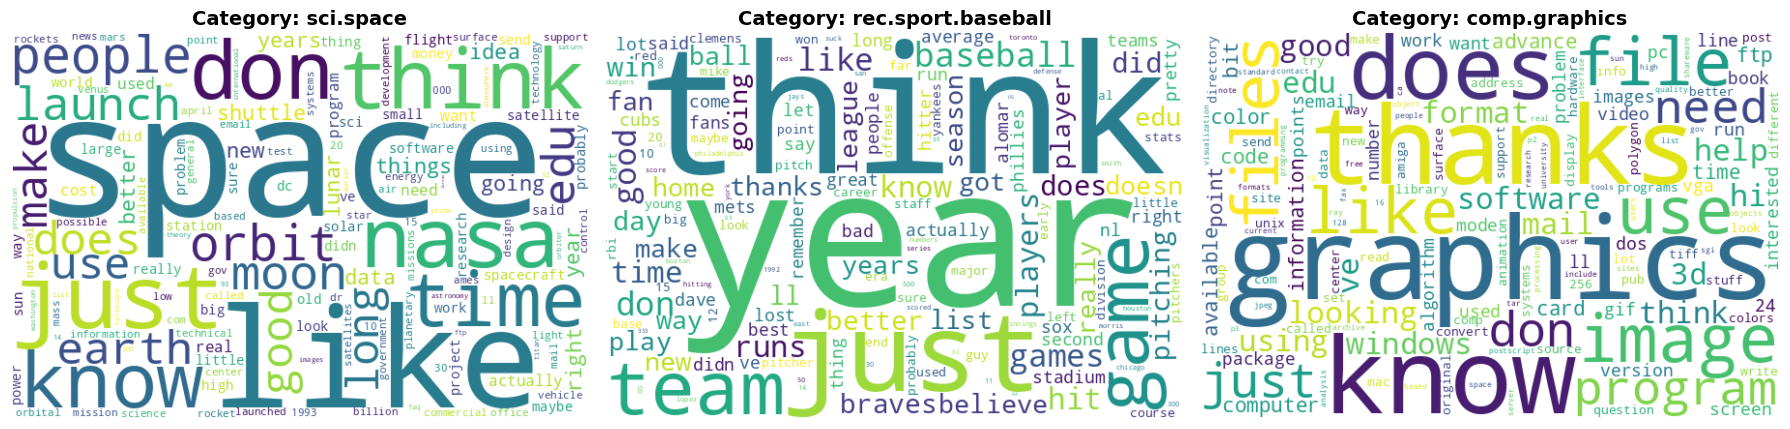

In [5]:

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, cat_name in enumerate(categories):
    # Filter documents belonging to this category
    cat_idx = dataset.target_names.index(cat_name)
    docs = [doc for doc, target in zip(dataset.data, dataset.target) if target == cat_idx]

    # Calculate TF-IDF to penalize common generic words
    vectorizer = TfidfVectorizer(stop_words='english', max_features=150, min_df=2)
    tfidf_matrix = vectorizer.fit_transform(docs)

    # Calculate mean TF-IDF score per term across the category
    mean_weights = dict(zip(
        vectorizer.get_feature_names_out(),
        tfidf_matrix.toarray().mean(axis=0)
    ))

    # Generate Word Cloud using TF-IDF frequencies
    wc = WordCloud(
        width=600,
        height=400,
        background_color='white',
        colormap='viridis'
    ).generate_from_frequencies(mean_weights)

    # Plot
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f"Category: {cat_name}", fontsize=14, fontweight='bold')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

TfidfVectorizer converts a collection of raw text documents into a numerical matrix of TF-IDF features, which machine learning models and mathematical algorithms can actually process.

Machine learning algorithms and numerical routines cannot understand raw text directly; they require numbers. Simply counting words (like CountVectorizer) fails because frequent, generic words dominate. TfidfVectorizer solves this by balancing local frequency against global rarity.